# Sentiment Analyzer

In this project, we analyze a dataset of 20,000 customer reviews to classify them into **Positive**, **Neutral**, and **Negative** sentiments. We use classical Natural Language Processing (NLP) techniques and compare two models: Multinomial Naive Bayes and Logistic Regression.



## 2. Import Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')

# Download necessary NLTK datasets
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)



True

## 3. Load Dataset

We load the prepared 20,000-review dataset which was sampled from `neonwatty/amazon_reviews_multi`.


In [2]:
df = pd.read_csv('../data/customer_reviews.csv')
# Ensure no missing values in text
df['review_body'] = df['review_body'].fillna('')
df.head()



,review_body,sentiment
0,One of the locks does not work. but for the pr...,Neutral
1,This is not an accurate thermometer. Consisten...,Negative
2,"Great, well made, shirts at a fantastic price....",Neutral
3,Charge Port cover is broken with less than 4 m...,Negative
4,I absolutely love this thing. If I actually wo...,Positive


## 4. Dataset Inspection


In [3]:
print(f"Total reviews: {len(df)}")
print("\nMissing values:")
print(df.isnull().sum())



Total reviews: 20000

Missing values:
review_body    0
sentiment      0
dtype: int64


## 5. Sentiment Label Creation

During the dataset preparation phase, the raw `stars` ratings were mapped to sentiment classes as follows:
- 1–2 stars → **Negative**
- 3 stars   → **Neutral**
- 4–5 stars → **Positive**

Below is the distribution of these sentiment labels.



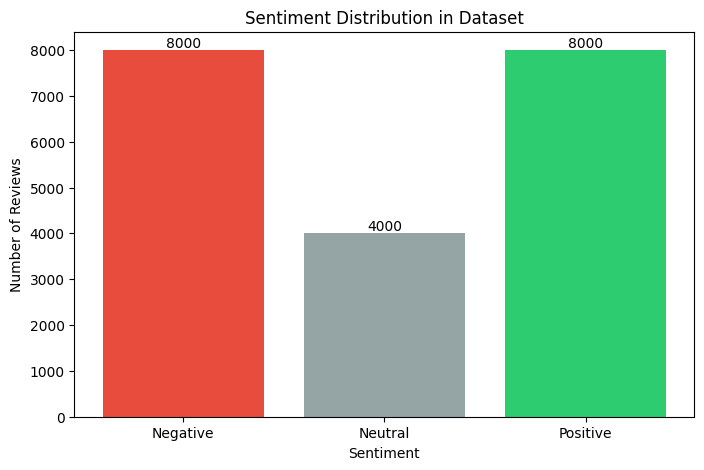

In [4]:
plt.figure(figsize=(8, 5))
sentiment_counts = df['sentiment'].value_counts()[['Negative', 'Neutral', 'Positive']]
bars = plt.bar(sentiment_counts.index, sentiment_counts.values, color=['#e74c3c', '#95a5a6', '#2ecc71'])
plt.title('Sentiment Distribution in Dataset')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.bar_label(bars)
plt.show()



## 6. Text Preprocessing

We clean and standardize the text data so it is ready for machine learning algorithms.

1. **Basic text cleaning**: Converts text to lowercase, removes punctuation/non-alphabetic noise, and normalizes whitespace.
2. **Tokenization (NLTK)**: Splits the string into individual words.
3. **Stop-word Removal**: Removes common English words. We explicitly **preserve negation words** (like "not", "no", "never") because they are vital for determining sentiment.
4. **Stemming (PorterStemmer)**: Reduces words to their root form (e.g., "running" -> "run").



In [5]:
# Define custom stop-words list preserving negations
stop_words = set(stopwords.words('english'))
negation_words = {'no', 'not', 'never', 'none', 'neither', 'nor', 'cannot', "couldn't", "shouldn't", "wouldn't", "didn't", "doesn't", "hasn't", "haven't", "isn't", "aren't", "wasn't", "weren't"}
stop_words = stop_words - negation_words

stemmer = PorterStemmer()

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    
    tokens = word_tokenize(text)
    tokens = [stemmer.stem(word) for word in tokens if word not in stop_words]
    
    return ' '.join(tokens)

# Apply preprocessing (this takes a few seconds)
df['processed_text'] = df['review_body'].apply(preprocess_text)
df[['review_body', 'processed_text', 'sentiment']].head()



,review_body,processed_text,sentiment
0,One of the locks does not work. but for the pr...,one lock not work price one expect,Neutral
1,This is not an accurate thermometer. Consisten...,not accur thermomet consist get degre read sho...,Negative
2,"Great, well made, shirts at a fantastic price....",great well made shirt fantast price smallest e...,Neutral
3,Charge Port cover is broken with less than 4 m...,charg port cover broken less month use,Negative
4,I absolutely love this thing. If I actually wo...,absolut love thing actual work bet would see e...,Positive


## 7. Train/Test Split

We split the data into 80% training and 20% testing. We use **stratification** to ensure that both splits perfectly preserve our sentiment distribution (40% Negative, 20% Neutral, 40% Positive).



In [6]:
X = df['processed_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")



Training samples: 16000
Test samples: 4000


## 8. TF-IDF Vectorization

We convert our processed text into numbers using **TF-IDF (Term Frequency-Inverse Document Frequency)**.
- **What it does**: It counts word frequencies in a review but penalizes words that appear too commonly across all reviews, highlighting uniquely important words.
- **Why it's suitable**: It's computationally lightweight and performs exceptionally well with classical algorithms like Naive Bayes and Logistic Regression.
- **Data Leakage Prevention**: We fit the `TfidfVectorizer` **only** on the training data. This simulates a real-world scenario where the model encounters unseen text.



In [7]:
# Initialize TF-IDF Vectorizer (unigrams, drop very rare words, max 10000 features)
vectorizer = TfidfVectorizer(max_features=10000, min_df=5)

# Fit on Train, Transform Test
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"Number of TF-IDF features: {len(vectorizer.get_feature_names_out())}")
print(f"Training matrix shape: {X_train_tfidf.shape}")
print(f"Test matrix shape: {X_test_tfidf.shape}")



Number of TF-IDF features: 3612
Training matrix shape: (16000, 3612)
Test matrix shape: (4000, 3612)


## 9. Multinomial Naive Bayes

Naive Bayes is a probabilistic classifier based on Bayes' Theorem. It is highly suitable for text classification because it specifically expects discrete features (like TF-IDF scores) and works exceptionally well with sparse matrices. It is fast, simple, and often serves as a strong baseline.



In [8]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_preds = nb_model.predict(X_test_tfidf)



## 10. Logistic Regression

Logistic Regression is a linear model that learns the relationship between the TF-IDF features and the probability of a review belonging to a specific class. By assigning positive or negative weights to different words, it determines whether certain terms strongly push the prediction towards Positive, Negative, or Neutral.



In [9]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)
lr_preds = lr_model.predict(X_test_tfidf)



## 11. Model Evaluation

We evaluate our models using the following metrics (using a weighted average for multiclass):
- **Accuracy**: The overall percentage of correctly predicted sentiments.
- **Precision**: Out of all reviews predicted as a certain class, how many were actually that class? (Quality)
- **Recall**: Out of all reviews that are actually a certain class, how many did we successfully find? (Coverage)
- **F1-score**: The harmonic mean of Precision and Recall. It provides a balanced score.



In [10]:
def get_metrics(y_true, y_pred):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, average='weighted'),
        recall_score(y_true, y_pred, average='weighted'),
        f1_score(y_true, y_pred, average='weighted')
    ]

results = {
    'Model': ['Multinomial Naive Bayes', 'Logistic Regression'],
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1-score': []
}

nb_metrics = get_metrics(y_test, nb_preds)
lr_metrics = get_metrics(y_test, lr_preds)

for i, metric in enumerate(['Accuracy', 'Precision', 'Recall', 'F1-score']):
    results[metric] = [nb_metrics[i], lr_metrics[i]]

results_df = pd.DataFrame(results)
display(results_df)



,Model,Accuracy,Precision,Recall,F1-score
0,Multinomial Naive Bayes,0.6665,0.633668,0.6665,0.604051
1,Logistic Regression,0.6840,0.653090,0.6840,0.658715


## 12. Confusion Matrices

A **Confusion Matrix** shows exactly where the model gets confused (e.g., predicting a Negative review as Neutral).



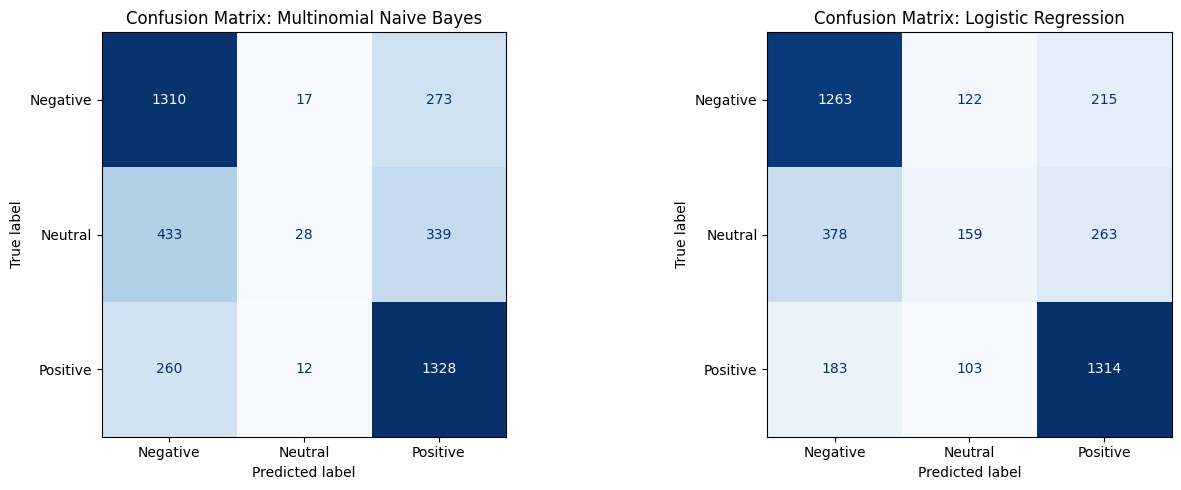

In [11]:
labels = ['Negative', 'Neutral', 'Positive']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(y_test, nb_preds, labels=labels, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix: Multinomial Naive Bayes')

ConfusionMatrixDisplay.from_predictions(y_test, lr_preds, labels=labels, ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Confusion Matrix: Logistic Regression')

plt.tight_layout()
plt.show()



## 13. Model Comparison


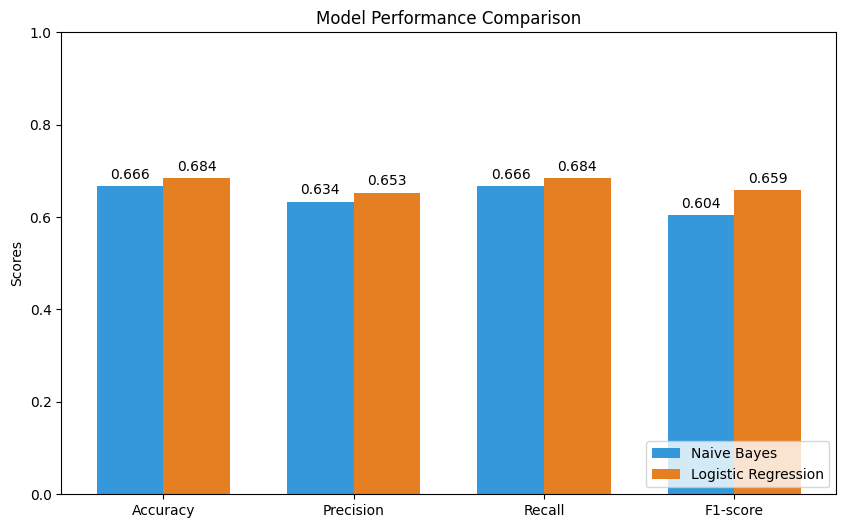

In [12]:
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-score']
nb_scores = results_df.iloc[0][metrics_to_plot].values
lr_scores = results_df.iloc[1][metrics_to_plot].values

x = np.arange(len(metrics_to_plot))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, nb_scores, width, label='Naive Bayes', color='#3498db')
rects2 = ax.bar(x + width/2, lr_scores, width, label='Logistic Regression', color='#e67e22')

ax.set_ylabel('Scores')
ax.set_title('Model Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot)
ax.set_ylim([0, 1.0])
ax.legend(loc='lower right')

ax.bar_label(rects1, padding=3, fmt='%.3f')
ax.bar_label(rects2, padding=3, fmt='%.3f')

plt.show()



## 14. Sample Predictions

Below are demonstration predictions on a few manually provided example reviews using our trained **Logistic Regression** model.



In [13]:
sample_reviews = [
    "This product exceeded my expectations! The quality is amazing.",
    "It broke after 2 days of use. Terrible customer service, will not buy again.",
    "It's okay. Does the job, but nothing special for the price.",
    "Not an accurate device. Consistently gives wrong readings."
]

# Preprocess and vectorize the unseen samples
sample_processed = [preprocess_text(rev) for rev in sample_reviews]
sample_tfidf = vectorizer.transform(sample_processed)

# Predict
sample_preds = lr_model.predict(sample_tfidf)

for rev, pred in zip(sample_reviews, sample_preds):
    print(f"\nReview: {rev}")
    print(f"Predicted Sentiment: {pred}")




Review: This product exceeded my expectations! The quality is amazing.
Predicted Sentiment: Positive

Review: It broke after 2 days of use. Terrible customer service, will not buy again.
Predicted Sentiment: Negative

Review: It's okay. Does the job, but nothing special for the price.
Predicted Sentiment: Neutral

Review: Not an accurate device. Consistently gives wrong readings.
Predicted Sentiment: Negative


## 15. Final Conclusion

- **Logistic Regression performed better overall**.
- Its accuracy was **68.40%** and its weighted F1-score was **65.87%**.
- **Multinomial Naive Bayes** achieved **66.65%** accuracy and **60.41%** weighted F1-score.
- While both models successfully identified explicitly Positive and Negative reviews, **Logistic Regression handled the Neutral class better**. Naive Bayes almost completely ignored the Neutral class (defaulting to Positive or Negative), whereas Logistic Regression was able to identify nuanced middle-ground reviews.

